# 02.6 · Curves: polynomial regression and the first look at overfitting

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/cloudops-one/training-ai-ml/blob/main/modules/02-regression/06-polynomial-and-overfitting/lesson.ipynb)

Read the [README](README.md) first. Here: a curved dataset, a line that cannot bend, a curve that fits, a curve that fits *too well*, and the test-set habit that tells them apart. Then the same experiment on the real customers.

## 1. Twelve ad campaigns

In [1]:
# --- data helper: works locally and on Colab -------------------------------
from pathlib import Path
import urllib.request

def data_path(name):
    """Return a local path to data/<name>, downloading from GitHub on Colab."""
    for parent in [Path.cwd(), *Path.cwd().parents]:
        candidate = parent / "data" / name
        if candidate.exists():
            return candidate
    url = f"https://raw.githubusercontent.com/cloudops-one/training-ai-ml/main/data/{name}"
    dest = Path(name)
    if not dest.exists():
        urllib.request.urlretrieve(url, dest)
    return dest

import numpy as np, pandas as pd
# ShopWave ran 12 ad campaigns last year (spend in £k) and counted the extra orders each brought.
ads = pd.DataFrame({"ad_spend_k": [0.5, 1, 1.5, 2, 3, 4, 5, 6, 7, 8, 9, 10],
                    "extra_orders": [42, 62, 71, 78, 100, 112, 135, 158, 155, 165, 184, 193]})
# Thirty campaigns from this year, held back to test on (same process, new noise)
rng = np.random.default_rng(3)
test_x = np.sort(rng.uniform(0.5, 10, 30))
ads_test = pd.DataFrame({"ad_spend_k": test_x, "extra_orders": (60 * np.sqrt(test_x) + rng.normal(0, 8, 30)).round(0)})
ads

,ad_spend_k,extra_orders
0,0.5,42
1,1.0,62
2,1.5,71
3,2.0,78
4,3.0,100
5,4.0,112
6,5.0,135
7,6.0,158
8,7.0,155
9,8.0,165


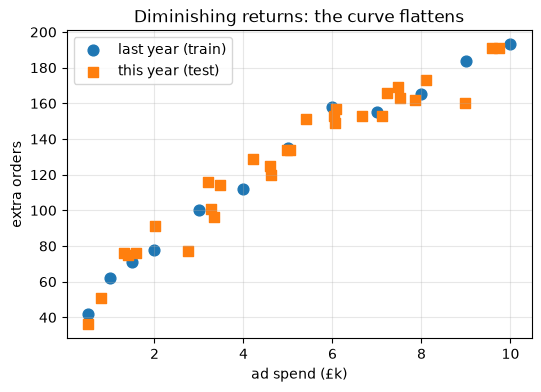

In [2]:
import matplotlib.pyplot as plt
plt.figure(figsize=(6, 4))
plt.scatter(ads["ad_spend_k"], ads["extra_orders"], s=60, label="last year (train)")
plt.scatter(ads_test["ad_spend_k"], ads_test["extra_orders"], s=60, marker="s", color="tab:orange", label="this year (test)")
plt.xlabel("ad spend (£k)"); plt.ylabel("extra orders"); plt.title("Diminishing returns: the curve flattens")
plt.legend(); plt.grid(alpha=.3); plt.show()

## 2. Polynomial features by hand, then in code

For $x = 3$ and degree 2 the feature row is $[1, 3, 9]$; for degree 3 it is $[1, 3, 9, 27]$. `PolynomialFeatures` builds those columns; `LinearRegression` then fits a straight line *through the new columns*, which is a curve in the original $x$.

(We scale $x$ first so that $x^7$ does not reach ten million and wreck the arithmetic; the fitted curve is identical.)

In [3]:
from sklearn.preprocessing import PolynomialFeatures
pf = PolynomialFeatures(3)
print("columns:", pf.fit(ads[["ad_spend_k"]]).get_feature_names_out())
print(pf.transform(pd.DataFrame({"ad_spend_k": [3.0, 10.0]})))

columns: ['1' 'ad_spend_k' 'ad_spend_k^2' 'ad_spend_k^3']
[[   1.    3.    9.   27.]
 [   1.   10.  100. 1000.]]


## 3. Degree 1, 2 and 9: train error vs test error

In [4]:
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import make_pipeline

def poly_model(degree):
    """Scale x, build x, x², …, x^degree, fit a line through them."""
    return make_pipeline(StandardScaler(), PolynomialFeatures(degree), LinearRegression())

from sklearn.metrics import mean_absolute_error
X_tr, y_tr = ads[["ad_spend_k"]], ads["extra_orders"]
X_te, y_te = ads_test[["ad_spend_k"]], ads_test["extra_orders"]

rows = []
for d in [1, 2, 3, 5, 9]:
    m = poly_model(d).fit(X_tr, y_tr)
    rows.append({"degree": d, "train MAE": mean_absolute_error(y_tr, m.predict(X_tr)),
                 "test MAE": mean_absolute_error(y_te, m.predict(X_te)),
                 "predict at £12k": m.predict(pd.DataFrame({"ad_spend_k": [12.0]}))[0]})
pd.DataFrame(rows).round(1)

,degree,train MAE,test MAE,predict at £12k
0,1,5.9,8.9,232.8
1,2,4.0,6.7,201.9
2,3,3.6,6.5,215.6
3,5,3.6,6.3,317.8
4,9,0.8,7.9,9631.7


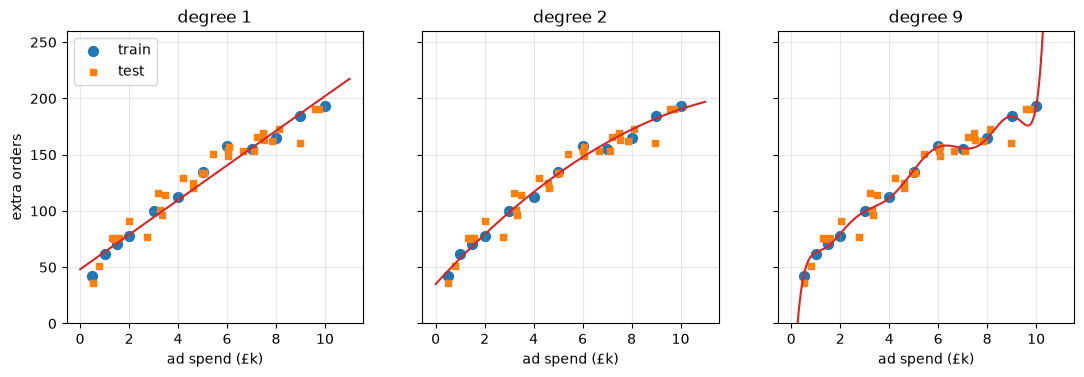

In [5]:
grid = pd.DataFrame({"ad_spend_k": np.linspace(0, 11, 300)})
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8), sharey=True)
for ax, d in zip(axes, [1, 2, 9]):
    m = poly_model(d).fit(X_tr, y_tr)
    ax.scatter(X_tr, y_tr, s=50, label="train"); ax.scatter(X_te, y_te, s=20, marker="s", color="tab:orange", label="test")
    ax.plot(grid, m.predict(grid), color="tab:red")
    ax.set(title=f"degree {d}", xlabel="ad spend (£k)", ylim=(0, 260)); ax.grid(alpha=.3)
axes[0].set_ylabel("extra orders"); axes[0].legend()
plt.show()

Read the table and the pictures together:

- **Degree 1** (a line) cannot bend. It under-predicts at both ends and over-predicts in the middle: **underfitting**. Its train and test errors are both the worst of the sensible models.
- **Degree 2** bends once, follows the diminishing-returns shape, and cuts the test error by a quarter.
- **Degree 9** passes through almost every training point (train MAE under 1) and yet is *worse* than degree 2 on this year's campaigns: **overfitting**. Between the training points it wiggles; beyond them it is absurd. Its prediction for a £12k campaign is in the thousands when the true curve is around 210.

The training error alone would have told you degree 9 is best. **Only the held-out test set tells the truth.** From here on, every score you report is a test score.

## 4. The U-shaped curve

Plot test error against degree. This picture, in one form or another, appears in every ML course and every model you will ever tune.

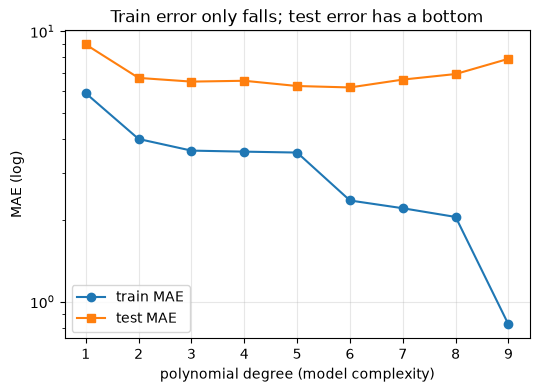

In [6]:
degrees = range(1, 10)
tr = [mean_absolute_error(y_tr, poly_model(d).fit(X_tr, y_tr).predict(X_tr)) for d in degrees]
te = [mean_absolute_error(y_te, poly_model(d).fit(X_tr, y_tr).predict(X_te)) for d in degrees]
plt.figure(figsize=(6, 4))
plt.plot(degrees, tr, marker="o", label="train MAE"); plt.plot(degrees, te, marker="s", label="test MAE")
plt.yscale("log"); plt.xlabel("polynomial degree (model complexity)"); plt.ylabel("MAE (log)")
plt.title("Train error only falls; test error has a bottom"); plt.legend(); plt.grid(alpha=.3); plt.show()

Left of the bottom: too simple, both errors high (underfit). Right of it: training error keeps falling while test error climbs (overfit). The bottom is the complexity you want. Module 04 gives you cross-validation to find it reliably with small data.

## 5. The real customers

Does bending help on next-quarter spend? Use `spend` as the one feature, hold out 20% of customers, and compare degrees. (`train_test_split` is the standard tool; lesson 04.1 covers it properly.)

In [7]:
# --- data helper: works locally and on Colab -------------------------------
from pathlib import Path
import urllib.request

def data_path(name):
    """Return a local path to data/<name>, downloading from GitHub on Colab."""
    for parent in [Path.cwd(), *Path.cwd().parents]:
        candidate = parent / "data" / name
        if candidate.exists():
            return candidate
    url = f"https://raw.githubusercontent.com/cloudops-one/training-ai-ml/main/data/{name}"
    dest = Path(name)
    if not dest.exists():
        urllib.request.urlretrieve(url, dest)
    return dest

import sys, pandas as pd
sys.path.insert(0, str(data_path("download.py").parent))
from download import ensure_online_retail

raw = pd.read_excel(ensure_online_retail(), sheet_name="Year 2010-2011")
print(raw.shape)
raw.head()


def clean_retail(df):
    """The standard ShopWave cleaning used from lesson 01.5 onwards."""
    out = df.copy()
    out = out[~out["Invoice"].astype(str).str.startswith("C")]   # drop cancellations
    out = out[(out["Quantity"] > 0) & (out["Price"] > 0)]         # drop returns / free items
    out = out.dropna(subset=["Customer ID"])                       # drop guest checkouts
    out = out.drop_duplicates()
    out["Customer ID"] = out["Customer ID"].astype(int)
    out["Revenue"] = out["Quantity"] * out["Price"]
    return out

sales = clean_retail(raw)
print(f"{len(raw):,} rows → {len(sales):,} after cleaning")


cutoff = pd.Timestamp("2011-09-01")
past = sales[sales["InvoiceDate"] < cutoff]
future = sales[(sales["InvoiceDate"] >= cutoff) & (sales["InvoiceDate"] < "2011-12-01")]

cust = past.groupby("Customer ID").agg(
    orders=("Invoice", "nunique"), spend=("Revenue", "sum"),
    products=("StockCode", "nunique"), items=("Quantity", "sum"),
    first_order=("InvoiceDate", "min"), last_order=("InvoiceDate", "max"),
    country=("Country", "first"))
cust["avg_order"] = cust["spend"] / cust["orders"]
cust["tenure_days"] = (cutoff - cust["first_order"]).dt.days
cust["days_since_last"] = (cutoff - cust["last_order"]).dt.days
cust["spend_next_quarter"] = future.groupby("Customer ID")["Revenue"].sum().reindex(cust.index).fillna(0)
cust = cust.drop(columns=["first_order", "last_order"])
print(f"{len(cust):,} customers; features from before {cutoff.date()}, target = spend Sep–Nov 2011")
cust.head()

(541910, 8)
541,910 rows → 392,693 after cleaning


3,317 customers; features from before 2011-09-01, target = spend Sep–Nov 2011


,orders,spend,products,items,country,avg_order,tenure_days,days_since_last,spend_next_quarter
Customer ID,,,,,,,,,
12346,1,77183.60,1,74215,United Kingdom,77183.600000,225,225,0.00
12347,5,2790.86,82,1590,Iceland,558.172000,267,29,1294.32
12348,3,1487.24,22,2124,Finland,495.746667,258,148,310.00
12350,1,334.40,17,197,Norway,334.400000,210,210,0.00
12352,5,1561.81,26,254,Norway,312.362000,196,162,944.23


In [8]:
import numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

def report(name, y_true, y_pred):
    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    r2 = r2_score(y_true, y_pred)
    print(f"{name:<28} MAE £{mae:8.1f}   RMSE £{rmse:8.1f}   R² {r2:6.3f}")

from sklearn.model_selection import train_test_split
Xr, yr = cust[["spend"]], cust["spend_next_quarter"]
Xr_tr, Xr_te, yr_tr, yr_te = train_test_split(Xr, yr, test_size=0.2, random_state=42)
for d in [1, 2, 3, 5]:
    m = poly_model(d).fit(Xr_tr, yr_tr)
    print(f"degree {d}   train R² {r2_score(yr_tr, m.predict(Xr_tr)):.3f}   ", end="")
    report("test", yr_te, m.predict(Xr_te))

degree 1   train R² 0.707   test                         MAE £   777.1   RMSE £  3938.2   R²  0.620
degree 2   train R² 0.713   test                         MAE £   773.1   RMSE £  3878.9   R²  0.632
degree 3   train R² 0.714   test                         MAE £   777.3   RMSE £  3798.8   R²  0.647
degree 5   train R² 0.663   test                         MAE £  1084.6   RMSE £  6730.3   R² -0.109


Training R² rises with degree, as it must. Test performance does not follow: a straight line in past spend is about as good as it gets with this one feature, and high degrees get wild on the wholesalers at the far right. Curves are a tool, not an upgrade; the test set decides whether they earned their place.

## Quiz answers

1. Because a polynomial in $x$ is *linear in the new columns* $x, x^2, x^3, \dots$: the coefficients still enter as a weighted sum, so least squares still works unchanged.
2. Training error can only fall (or stay) as degree rises; the model has strictly more freedom. It says nothing about new data.
3. Test error high *and* training error high: underfitting (too simple). Training error low but test error high: overfitting (too complex).
4. Hold out data the model never trained on and score there. Pick the complexity where held-out error is lowest.
5. No: a degree-9 polynomial through 12 points has memorised noise. Its prediction at £12k is absurd. The test rows, not the training fit, decide.

**Next:** [02.7 Decision tree regressor](../07-decision-tree-regressor/)